In [ ]:
!pip -q install pandas numpy openpyxl


In [ ]:
from google.colab import files
uploaded = files.upload()  # selecciona los ZIPs
ZIPS_DIR = "/content"


Saving 20250227-PRV-Eolico-Diciembre-2024.zip to 20250227-PRV-Eolico-Diciembre-2024.zip
Saving 20250227-PRV-Eolico-Noviembre-2024.zip to 20250227-PRV-Eolico-Noviembre-2024.zip
Saving 20250226-PRV-Eolico-Octubre-2024.zip to 20250226-PRV-Eolico-Octubre-2024.zip
Saving Eolico-Septiembre-2024.zip to Eolico-Septiembre-2024.zip
Saving Eolico-Agosto-2024.zip to Eolico-Agosto-2024.zip
Saving Eolico-Julio-2024.zip to Eolico-Julio-2024.zip
Saving Eolico-Junio-2024-v2.zip to Eolico-Junio-2024-v2.zip
Saving Eolico-Mayo-2024_v2.zip to Eolico-Mayo-2024_v2.zip
Saving Eolico-abril-2024.zip to Eolico-abril-2024.zip
Saving Eolico-Marzo-2024.zip to Eolico-Marzo-2024.zip
Saving Eolico-Febrero-2024.zip to Eolico-Febrero-2024.zip
Saving Eolico-Enero-2024.zip to Eolico-Enero-2024.zip


In [ ]:
import os, re, zipfile, io
import pandas as pd
from glob import glob

def extract_zip_folder(zip_path, extract_to):
    os.makedirs(extract_to, exist_ok=True)
    with zipfile.ZipFile(zip_path, 'r') as z:
        z.extractall(extract_to)

def find_real_eolico_excel(extracted_dir):
    """
    Devuelve la ruta al Excel de 'RealEolico' dentro de una carpeta extraída.
    Algunas variaciones de nombre: 'RealEolico - DIC24.xlsx', 'Real Eolico ...'
    """
    candidates = []
    for root, dirs, files in os.walk(extracted_dir):
        for f in files:
            fname = f.lower()
            # heurística tolerante
            if ('real' in fname) and ('eolico' in fname) and fname.endswith('.xlsx'):
                candidates.append(os.path.join(root, f))
    # Si hay varios, prioriza el que tenga 'real' al inicio
    if not candidates:
        return None
    candidates.sort(key=lambda p: os.path.basename(p).lower().startswith('real'))
    return candidates[0]

def read_real_eolico_df(xlsx_path):
    """
    Lee el Excel 'RealEolico - MES.xlsx' esperado con columnas: Valor, Nombre, Fecha, Hora
    """
    df = pd.read_excel(xlsx_path, sheet_name=0)
    # Normaliza nombres de columnas
    colmap = {c.lower(): c for c in df.columns}
    # Re-asigna robustamente
    rename = {}
    for c in df.columns:
        lc = c.lower().strip()
        if 'valor' in lc:
            rename[c] = 'Valor'
        elif 'nombre' in lc:
            rename[c] = 'Nombre'
        elif 'fecha' in lc:
            rename[c] = 'Fecha'
        elif lc.startswith('hora') or 'hora' in lc:
            rename[c] = 'Hora'
    df = df.rename(columns=rename)
    # Chequeo mínimo
    needed = {'Valor','Nombre','Fecha','Hora'}
    missing = needed - set(df.columns)
    if missing:
        raise ValueError(f"Faltan columnas {missing} en {xlsx_path}")
    return df[['Valor','Nombre','Fecha','Hora']]


In [ ]:
import shutil
BASE_EXTRACT = "/content/eolico_2024_extract"
if os.path.exists(BASE_EXTRACT):
    shutil.rmtree(BASE_EXTRACT)
os.makedirs(BASE_EXTRACT, exist_ok=True)

# Toma todos los ZIPs dentro de la carpeta
zip_paths = sorted(glob(os.path.join(ZIPS_DIR, "*.zip")))
print(f"Encontrados {len(zip_paths)} ZIPs.")
assert len(zip_paths) > 0, "No se encontraron ZIPs. Revisa ZIPS_DIR."

dfs = []
errores = []
for zp in zip_paths:
    month_dir = os.path.join(BASE_EXTRACT, os.path.splitext(os.path.basename(zp))[0])
    try:
        extract_zip_folder(zp, month_dir)
        xls_path = find_real_eolico_excel(month_dir)
        if not xls_path:
            raise FileNotFoundError("No se encontró Excel RealEolico en " + month_dir)
        dfm = read_real_eolico_df(xls_path)
        dfm['__source_zip__'] = os.path.basename(zp)
        dfs.append(dfm)
    except Exception as e:
        errores.append((zp, str(e)))

print("Meses leídos:", len(dfs))
if errores:
    print("Algunos ZIPs tuvieron problemas:")
    for z, msg in errores:
        print(" -", os.path.basename(z), "->", msg)

full = pd.concat(dfs, ignore_index=True).dropna(subset=['Fecha','Hora','Nombre','Valor'])
full.head()



Encontrados 12 ZIPs.
Meses leídos: 12


,Valor,Nombre,Fecha,Hora,__source_zip__
0,8.32,PE PUNTA SIERRA,2024-10-01,1,20250226-PRV-Eolico-Octubre-2024.zip
1,67.00,PE AURORA,2024-10-01,1,20250226-PRV-Eolico-Octubre-2024.zip
2,101.70,PE SARCO,2024-10-01,1,20250226-PRV-Eolico-Octubre-2024.zip
3,2.30,PE TOTORAL,2024-10-01,1,20250226-PRV-Eolico-Octubre-2024.zip
4,127.80,PE SAN JUAN,2024-10-01,1,20250226-PRV-Eolico-Octubre-2024.zip


In [ ]:
# Normaliza tipos
full['Fecha'] = pd.to_datetime(full['Fecha'], errors='coerce')
# 'Hora' llega usualmente como 1..24. Restamos 1 hora para alinear a la hora UTC local estándar del reporte.
# (Si el coordinador define otra convención, ajusta aquí.)
full['Hora'] = full['Hora'].astype(int).clip(1, 24)

# Construye timestamp: Fecha + (Hora-1) horas
full['timestamp'] = full['Fecha'] + pd.to_timedelta(full['Hora'] - 1, unit='h')

# Ordena
full = full.sort_values(['Nombre','timestamp'])
full = full[['timestamp','Nombre','Valor','__source_zip__']]

# Resumen rápido
n_parks = full['Nombre'].nunique()
ts_min, ts_max = full['timestamp'].min(), full['timestamp'].max()
print(f"Parques únicos: {n_parks}")
print(f"Rango temporal (min..max): {ts_min} .. {ts_max}")


Parques únicos: 51
Rango temporal (min..max): 2024-01-01 00:00:00 .. 2024-12-31 23:00:00


In [ ]:
parks = sorted(full['Nombre'].unique().tolist())
print(f"Se detectaron {len(parks)} parques.\n")
for i, p in enumerate(parks[:50], 1):  # muestra hasta 50 por pantalla
    print(f"{i:3d}. {p}")
if len(parks) > 50:
    print("... (hay más)")

# Selección por nombre exacto o por índice:
modo = input("\nEscribe 'idx' para elegir por índice o 'nom' para escribir el nombre exacto: ").strip().lower()
if modo == 'idx':
    idx = int(input("Número de parque (índice mostrado): ").strip())
    assert 1 <= idx <= len(parks), "Índice fuera de rango."
    selected_park = parks[idx-1]
else:
    selected_park = input("Escribe el nombre EXACTO del parque (copiar-pegar recomendado): ").strip()

print("Seleccionado:", selected_park)


Se detectaron 51 parques.

  1. PE ALENA
  2. PE ATACAMA
  3. PE AURORA
  4. PE CABO LEONES
  5. PE CABO LEONES II
  6. PE CABO LEONES III
  7. PE CALAMA
  8. PE CAMPO LINDO
  9. PE CANELA
 10. PE CANELA II
 11. PE CARDONAL
 12. PE CERRO TIGRE
 13. PE CUEL
 14. PE EL ARRAYAN
 15. PE EL MAITEN
 16. PE LA ESPERANZA
 17. PE LA ESTRELLA
 18. PE LA FLOR
 19. PE LEBU
 20. PE LLANOS DEL  VIENTO
 21. PE LLANOS DEL VIENTO
 22. PE LOMAS DE DUQUECO
 23. PE LOS BUENOS AIRES
 24. PE LOS CURUROS
 25. PE LOS OLMOS
 26. PE MALLECO NORTE
 27. PE MALLECO SUR
 28. PE MESAMAVIDA
 29. PE MONTE REDONDO
 30. PE NEGRETE
 31. PE PUELCHE SUR
 32. PE PUNTA COLORADA
 33. PE PUNTA PALMERAS
 34. PE PUNTA SIERRA
 35. PE RENAICO I
 36. PE RENAICO II
 37. PE SAN GABRIEL
 38. PE SAN JUAN
 39. PE SAN MATIAS
 40. PE SAN PEDRO
 41. PE SAN PEDRO II
 42. PE SARCO
 43. PE SIERRA GORDA ESTE
 44. PE TALINAY ORIENTE
 45. PE TALINAY PONIENTE
 46. PE TALTAL
 47. PE TCHAMMA
 48. PE TOLPAN SUR
 49. PE TOTORAL
 50. PE UCUQUER II
...

In [ ]:
sel = full[full['Nombre'] == selected_park].copy()

# Reindexar a frecuencia horaria continua en el rango observado para esa PE
tmin, tmax = sel['timestamp'].min(), sel['timestamp'].max()
rng = pd.date_range(tmin, tmax, freq='h')

# Agrupar por timestamp (puede haber duplicados en el Excel)
series = sel.groupby('timestamp')['Valor'].mean().sort_index()

# Reindexar a rango horario continuo
series = series.reindex(rng)

# Limpieza de faltantes: puedes elegir el método que prefieras
# Opción 1: rellenar con interpolación lineal y extremos con ff/bfill
series_clean = series.interpolate(limit_direction='both').ffill().bfill()

print("PE:", selected_park)
print("Observaciones totales:", series_clean.size)
print("Faltantes antes de limpiar:", series.isna().sum())
print("Faltantes después de limpiar:", series_clean.isna().sum())

# Vista rápida
series_clean.tail(10)


PE: PE ALENA
Observaciones totales: 8784
Faltantes antes de limpiar: 1
Faltantes después de limpiar: 0


,Valor
2024-12-31 14:00:00,27.98
2024-12-31 15:00:00,27.98
2024-12-31 16:00:00,27.99
2024-12-31 17:00:00,27.98
2024-12-31 18:00:00,27.98
2024-12-31 19:00:00,28.11
2024-12-31 20:00:00,61.48
2024-12-31 21:00:00,71.00
2024-12-31 22:00:00,68.38
2024-12-31 23:00:00,63.49


In [ ]:
!pip -q install statsmodels pmdarima matplotlib


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 30.4 MB/s eta 0:00:00


2) Diagnóstico rápido de estacionariedad (ADF/KPSS) y ACF/PACF

En el paper ajustan ARMA(2,2) y validan con pruebas sobre residuos. Aquí te muestro tests previos por si necesitas diferenciar; si los p-values indican no estacionaria, puedes pasar a ARIMA(2,1,2) o diferenciar a mano.

Qué hace: inspección básica. Si la serie parece no estacionaria, considera:

usar order=(2,1,2) (ARIMA) o

diferenciar: y = y.diff().dropna() y luego ajustar ARMA(2,2) a la serie diferenciada.
(En lo que sigue, muestro ARMA(2,2) puro sobre y para mantenernos cercanos al paper.)

Estacionariedad (sobre la serie original):
ADF: stat=-11.824  p=0.0000
KPSS: stat=0.100  p=0.1000


/tmp/ipython-input-2757628680.py:15: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  stat, p, *_ = kpss(series, regression='c', nlags='auto')


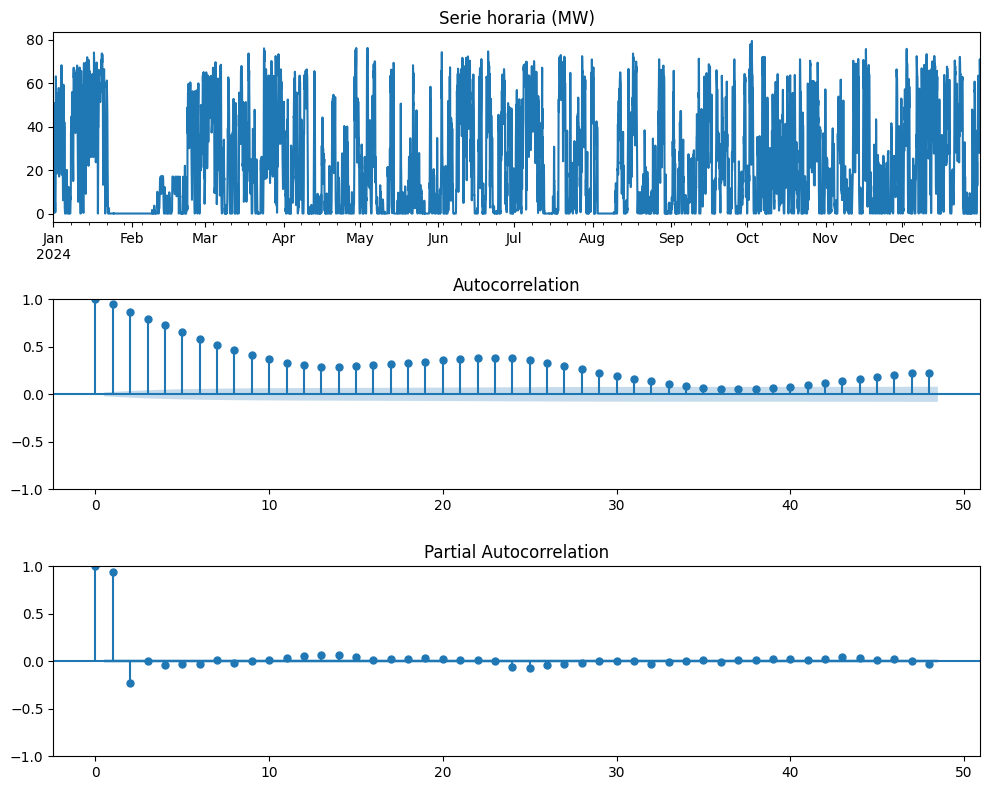

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

y = series_clean.astype(float).copy()   # <-- tu serie (MW) de la PE elegida

def adf_test(series):
    stat, p, *_ = adfuller(series, autolag='AIC')
    print(f"ADF: stat={stat:.3f}  p={p:.4f}")

def kpss_test(series):
    stat, p, *_ = kpss(series, regression='c', nlags='auto')
    print(f"KPSS: stat={stat:.3f}  p={p:.4f}")

print("Estacionariedad (sobre la serie original):")
adf_test(y)
try:
    kpss_test(y)
except:
    print("KPSS no disponible (puede fallar en ciertas versiones/series).")

fig, axes = plt.subplots(3, 1, figsize=(10,8))
y.plot(ax=axes[0], title='Serie horaria (MW)')
plot_acf(y, ax=axes[1], lags=48)
plot_pacf(y, ax=axes[2], lags=48)
plt.tight_layout()
plt.show()


3) Ajuste del ARMA(2,2) (MLE) y extracción de parámetros

Como en el paper: modelo con constante, AR(2) y MA(2). Luego validamos residuos (Ljung–Box) y efectos ARCH.

Qué hace:

Ajusta por máxima verosimilitud.

Imprime const, φ1, φ2, θ1, θ2, σ² y la media estacionaria μ (como referencia).

Valida residuos con Ljung–Box (queremos p-values altos) y ARCH (queremos p-value alto).

Si estos tests salen “bien”, estás en la misma línea que el paper.

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/statespace/sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'


                               SARIMAX Results                                
Dep. Variable:                  Valor   No. Observations:                 8784
Model:                 ARIMA(2, 0, 2)   Log Likelihood              -29629.230
Date:                Thu, 11 Sep 2025   AIC                          59270.460
Time:                        17:17:36   BIC                          59312.944
Sample:                    01-01-2024   HQIC                         59284.933
                         - 12-31-2024                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         21.0416      2.482      8.478      0.000      16.177      25.906
ar.L1          1.9029      0.013    151.785      0.000       1.878       1.927
ar.L2         -0.9036      0.012    -75.234      0.0

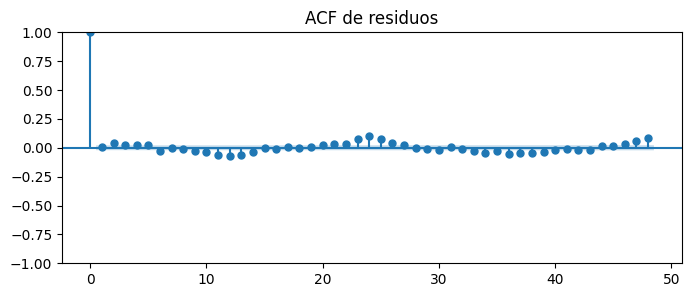

In [ ]:
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch

# Ajuste ARMA(2,2) (equivale a ARIMA(2,0,2))
model = ARIMA(y, order=(2,0,2), trend='c')
res = model.fit()

print(res.summary())

# Parámetros clave (los del paper)
params = res.params.to_dict()
phi1   = params.get('ar.L1', 0.0)
phi2   = params.get('ar.L2', 0.0)
theta1 = params.get('ma.L1', 0.0)
theta2 = params.get('ma.L2', 0.0)
const  = params.get('const', 0.0)
sigma2 = params.get('sigma2', 1.0)

# Media estacionaria (si aplica): mu = c / (1 - φ1 - φ2)
mu = const / (1 - phi1 - phi2) if abs(1 - phi1 - phi2) > 1e-8 else np.nan

print("\nParámetros ARMA(2,2):")
print({"const": const, "phi1": phi1, "phi2": phi2, "theta1": theta1, "theta2": theta2, "sigma2": sigma2, "mu": mu})

# Diagnóstico de residuos ~ ruido blanco (Ljung–Box)
lb = acorr_ljungbox(res.resid.dropna(), lags=[10, 20], return_df=True)
print("\nLjung-Box (residuos):")
print(lb)

# Efectos ARCH (heterocedasticidad condicional)
arch_stat, arch_p, *_ = het_arch(res.resid.dropna())
print(f"\nEngle ARCH test: stat={arch_stat:.3f}  p={arch_p:.4f}")

# Opcional: ACF de residuos
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf
fig, ax = plt.subplots(figsize=(8,3))
plot_acf(res.resid.dropna(), ax=ax, lags=48)
ax.set_title("ACF de residuos")
plt.show()


4) Generación de escenarios (Monte Carlo) — método 1 (directo del fit)

Como en el paper, generamos trayectorias horarias a futuro a partir del estado final del modelo. Este método es simple y correcto.

Qué hace:

Produce una matriz H × N con escenarios (como las 1,500 trayectorias del paper; sube N si quieres).

anchor='end' usa el “estado” al final de tu muestra, coherente con pronóstico/escenarios.

In [ ]:
# H = horizonte (horas), N = número de escenarios
H = 24      # p.ej., 24 h adelante
N = 500     # p.ej., 500 trayectorias

# Simulaciones (usa la parametrización y estado del modelo ajustado)
sims = res.simulate(nsimulations=H, repetitions=N, anchor='end')  # shape (H, N)

# Índice temporal futuro
freq = y.index.freq or pd.infer_freq(y.index)
future_index = pd.date_range(y.index[-1] + pd.tseries.frequencies.to_offset(freq),
                             periods=H, freq=freq)

scenarios_df = pd.DataFrame(sims, index=future_index)
scenarios_df.head()


Valor                                              \
                           0          1          2          3          4     
2025-01-01 00:00:00  63.019246  64.760685  68.630749  53.224592  64.547625   
2025-01-01 01:00:00  54.764449  59.773623  69.457714  38.532069  74.694632   
2025-01-01 02:00:00  50.005500  49.285276  58.749594  28.946536  66.280173   
2025-01-01 03:00:00  43.106282  35.386162  51.147976  32.692103  55.375009   
2025-01-01 04:00:00  48.331090  19.954544  37.799168  39.273705  52.873169   

                                                                            \
                           5          6          7          8          9     
2025-01-01 00:00:00  55.163560  59.040925  55.447869  51.574250  58.579319   
2025-01-01 01:00:00  50.271305  60.259360  62.948519  49.851117  54.654543   
2025-01-01 02:00:00  35.084632  62.979901  63.857601  61.391276  35.094155   
2025-01-01 03:00:00  32.142891  57.538810  57.955923  72.859950  30.217498   
2025-01-01 04:00:00  31.235538  61.950504  63.424193  77.452773  25.296151   

                     ...                                              \
                     ...        490        491        492        493   
2025-01-01 00:00:00  ...  61.640960  62.258819  55.789311  74.871391   
2025-01-01 01:00:00  ...  55.880732  62.946660  56.321265  66.746141   
2025-01-01 02:00:00  ...  37.870740  58.403698  48.368851  72.427307   
2025-01-01 03:00:00  ...  42.968882  60.232022  61.223677  76.816548   
2025-01-01 04:00:00  ...  40.751335  58.221709  56.484206  69.819278   

                                                                            \
                           494        495        496        497        498   
2025-01-01 00:00:00  65.742193  54.391008  61.839716  60.037119  68.609477   
2025-01-01 01:00:00  52.139024  37.133251  52.949462  48.359335  76.159935   
2025-01-01 02:00:00  55.280342  20.676039  42.057931  51.451812  82.412156   
2025-01-01 03:00:00  50.925568  21.999676  39.227429  58.590719  78.779012   
2025-01-01 04:00:00  56.667020  19.757829  38.212914  61.848795  66.044811   

                                
                           499  
2025-01-01 00:00:00  55.178178  
2025-01-01 01:00:00  39.540246  
2025-01-01 02:00:00  40.894121  
2025-01-01 03:00:00  46.845178  
2025-01-01 04:00:00  54.256130  

[5 rows x 500 columns]

5) Generación de escenarios — método 2 (manual, con warm-up tipo paper)

Si quieres controlar un warm-up (p.ej. 140 h) y estados iniciales explícitos (últimos dos valores y residuos), usa esta versión

Qué hace:

Replica el warm-up de 140 h del paper (ajústalo si quieres).

Te da el mismo output H×N, pero con control fino de semilla, estados y warm-up.

In [ ]:
import numpy as np

def simulate_arma22(phi1, phi2, theta1, theta2, const, sigma2,
                    x_tm1, x_tm2, e_tm1, e_tm2,
                    H, n_paths, burnin=140, seed=None):
    """
    x_t = c + φ1 x_{t-1} + φ2 x_{t-2} + e_t + θ1 e_{t-1} + θ2 e_{t-2},
    e_t ~ N(0, sigma2)
    Devuelve (H, n_paths)
    """
    rng = np.random.default_rng(seed)
    out = np.zeros((H, n_paths))
    sd = np.sqrt(sigma2)

    for p in range(n_paths):
        # Warm-up para disipar condiciones iniciales (como en el paper)
        x1, x2 = x_tm1, x_tm2
        e1, e2 = e_tm1, e_tm2
        for _ in range(burnin):
            e = rng.normal(0, sd)
            x = const + phi1*x1 + phi2*x2 + e + theta1*e1 + theta2*e2
            x2, x1, e2, e1 = x1, x, e1, e

        # Trayectoria de interés
        x1, x2 = x_tm1, x_tm2
        e1, e2 = e_tm1, e_tm2
        for t in range(H):
            e = rng.normal(0, sd)
            x = const + phi1*x1 + phi2*x2 + e + theta1*e1 + theta2*e2
            out[t, p] = x
            x2, x1, e2, e1 = x1, x, e1, e

    return out

# Estados iniciales (últimos datos y residuos del fit)
x_tm1 = y.iloc[-1]
x_tm2 = y.iloc[-2]
resid = res.resid.dropna().values
e_tm1 = resid[-1] if len(resid) >= 1 else 0.0
e_tm2 = resid[-2] if len(resid) >= 2 else 0.0

H = 24
N = 500
paths = simulate_arma22(phi1, phi2, theta1, theta2, const, sigma2,
                        x_tm1, x_tm2, e_tm1, e_tm2,
                        H=H, n_paths=N, burnin=140, seed=123)

scenarios_wu = pd.DataFrame(paths, index=future_index)  # (H, N)
scenarios_wu.head()


,0,1,2,3,4,5,6,7,8,9,...,490,491,492,493,494,495,496,497,498,499
2025-01-01 00:00:00,78.189708,81.234588,84.467114,78.090316,79.855701,69.901864,75.074115,89.263002,86.285910,81.486292,...,88.385701,71.995895,77.080091,80.146551,78.957553,80.970807,82.076868,73.658389,83.262239,93.126741
2025-01-01 01:00:00,117.092268,126.927255,118.965812,118.330227,117.190988,109.951374,109.007633,133.852112,129.663168,119.440789,...,121.607862,114.572405,114.560669,99.934037,112.922360,128.937080,113.292131,111.322514,115.994986,139.810132
2025-01-01 02:00:00,172.954640,173.445825,164.919758,179.086633,178.179848,178.892665,175.172636,181.112698,174.120692,176.843243,...,181.651910,171.028884,166.223054,150.241415,161.599046,184.591929,161.158208,177.132165,172.515477,188.430320
2025-01-01 03:00:00,238.526849,245.078725,218.873397,248.658085,244.787333,254.261561,243.184572,255.497300,236.634820,251.721805,...,236.631234,241.683110,241.484754,219.757115,235.357698,262.826511,233.786307,245.321678,246.751467,256.751332
2025-01-01 04:00:00,324.693292,331.476311,312.158599,339.230798,326.042778,343.174999,321.789015,332.392375,323.412138,347.543766,...,311.150894,323.555775,324.029600,303.011337,334.846652,339.969301,312.060308,339.158027,341.057118,338.661443


6) (Opcional) Visualización rápida y resumen

Qué acabas de hacer (y por qué está alineado con el paper)

Ajuste ARMA(2,2) con MLE sobre una serie horaria de una PE específica (igual enfoque que el paper).

Validación con Ljung–Box (ruido blanco en residuos) y ARCH (sin heterocedasticidad condicional), tal como reportan.

Escenarios Monte Carlo: generaste múltiples trayectorias horarias a futuro (H×N), con una versión simple (simulate) y otra con warm-up de 140 h al estilo del paper.

Parámetros obtenidos: const, φ1, φ2, θ1, θ2, σ² — los equivalentes a “los parámetros del modelo” que ellos estiman antes de simular.

Si quieres, el siguiente paso es guardar los escenarios (CSV/Parquet) y/o pasar estos escenarios al bloque de optimización (modelo adaptativo/no-adaptativo con joint chance constraints) como en el paper.

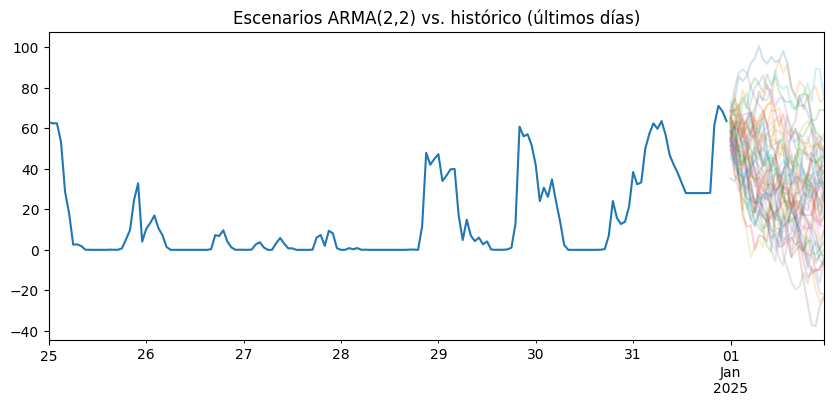

,0.1,0.5,0.9
2025-01-01 00:00:00,51.352695,60.119334,68.617564
2025-01-01 01:00:00,42.965918,57.172246,70.939082
2025-01-01 02:00:00,36.659238,54.510966,71.132235
2025-01-01 03:00:00,30.194639,51.960112,71.781971
2025-01-01 04:00:00,26.599073,49.681776,70.554439


In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10,4))
y.iloc[-7*24:].plot(ax=ax, label='Histórico reciente')  # última semana, por ejemplo
scenarios_df.iloc[:, :50].plot(ax=ax, alpha=0.2, legend=False)   # 50 escenarios para no saturar
ax.set_title('Escenarios ARMA(2,2) vs. histórico (últimos días)')
plt.show()

# Percentiles por hora (para ver banda de incertidumbre)
pcts = scenarios_df.quantile([0.1, 0.5, 0.9], axis=1).T
pcts.head()


1) Generar escenarios tipo paper

Ellos hicieron:

Monte Carlo con ARMA(2,2).

Warm-up de 140 horas.

1500 escenarios horarios.

Graficaron todas las trayectorias (colores) +

línea negra discontinua = mediana.

línea negra continua = percentil 10.

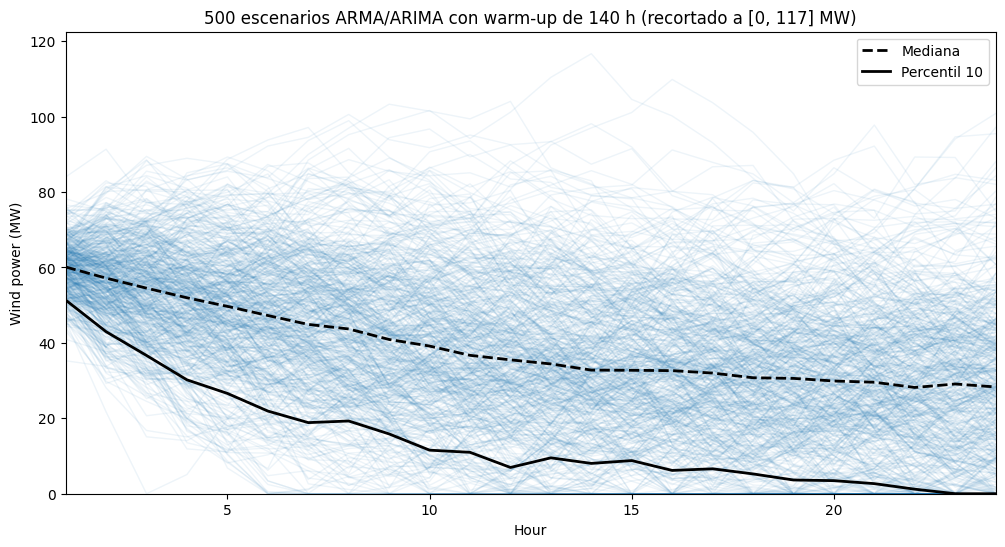

Guardado: escenarios_generados.csv


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==== Config ====
H = 24                # horizonte
N = scenarios_df.shape[1]  # número de escenarios ya generados
# techo de potencia: usa el histórico o un percentil alto para evitar outliers
Pmax = max(y.max(), scenarios_df.quantile(0.999).max())

# 1) Recorte físico [0, Pmax]
scen_clipped = scenarios_df.clip(lower=0, upper=Pmax)

# 2) Estadísticos (mediana y p10 por hora)
median = scen_clipped.median(axis=1)
p10    = scen_clipped.quantile(0.10, axis=1)

# 3) Eje x como horas 1..24 (opcional: rotular 7:00–6:00 si quieres copiar la figura)
x = np.arange(1, H+1)

fig, ax = plt.subplots(figsize=(12,6))
# nube de escenarios (muchas curvas -> alpha bajo)
ax.plot(x, scen_clipped.values, color="tab:blue", alpha=0.08, linewidth=1)
# líneas resumen
ax.plot(x, median.values, color="black", linestyle="--", linewidth=2, label="Mediana")
ax.plot(x, p10.values,    color="black", linewidth=2, label="Percentil 10")

ax.set_xlim(1, H)
ax.set_ylim(0, Pmax*1.05)
ax.set_xlabel("Hour")
ax.set_ylabel("Wind power (MW)")
ax.set_title(f"{N} escenarios ARMA/ARIMA con warm-up de 140 h (recortado a [0, {Pmax:.0f}] MW)")
ax.legend()
plt.show()

# 4) Guardar a CSV (cada columna = un escenario)
scen_clipped.to_csv("escenarios_generados.csv", index_label="timestamp_or_hour")
print("Guardado: escenarios_generados.csv")


                               SARIMAX Results                                
Dep. Variable:                  z_res   No. Observations:                 2880
Model:                 ARIMA(2, 0, 2)   Log Likelihood               -3809.349
Date:                Thu, 11 Sep 2025   AIC                           7628.698
Time:                        17:37:00   BIC                           7658.526
Sample:                    09-03-2024   HQIC                          7639.449
                         - 12-31-2024                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          1.3402      0.150      8.937      0.000       1.046       1.634
ar.L2         -0.4182      0.134     -3.128      0.002      -0.680      -0.156
ma.L1         -0.1901      0.150     -1.265      0.2

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/statespace/representation.py:374: FutureWarning: Unknown keyword arguments: dict_keys(['burn']).Passing unknown keyword arguments will raise a TypeError beginning in version 0.15.
  warnings.warn(msg, FutureWarning)


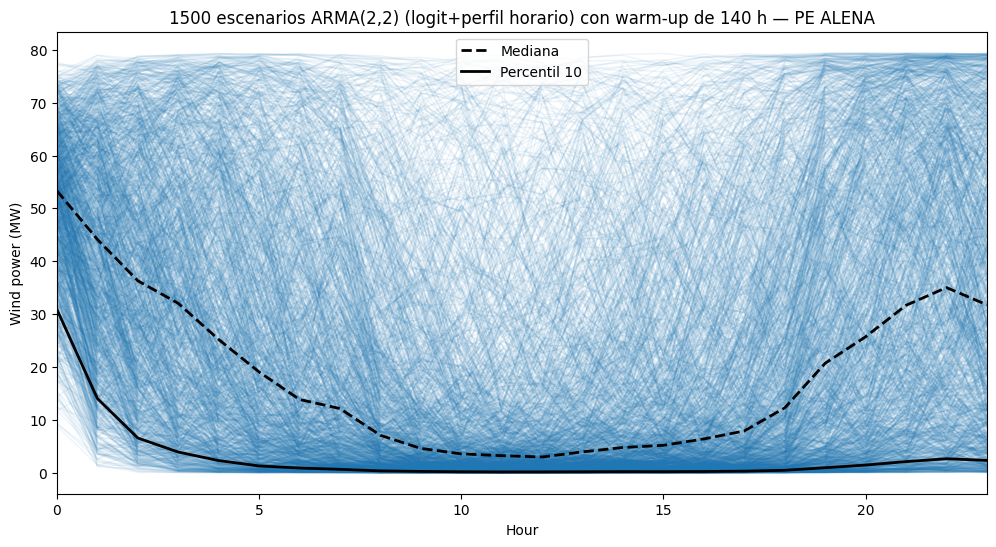

Guardado: escenarios_PE_ALENA_arma22_bounded.csv
Pmax usado (MW): 79.46


In [ ]:
# --- Configuración del experimento ---
# series_clean: tu serie horaria en MW para UNA PE, ya limpia y continua
pe_name     = selected_park           # o un string con el nombre de la PE
dias_hist   = 120                     # cuántos días hacia atrás usamos para estimar
H          = 24                       # horizonte en horas
N          = 1500                     # número de escenarios
burnin     = 140                      # warm-up como en el paper
eps        = 1e-3                     # margen para evitar 0 o 1 exactos en logit

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import expit, logit
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch

# 1) Submuestra histórica (últimos 'dias_hist' días)
y_all = series_clean.astype(float).copy()
y     = y_all.iloc[-dias_hist*24:]  # asumiendo frecuencia horaria

# 2) Potencia máxima (nombre de placa si la tienes; aquí usamos máximo observado razonable)
#    Para robustez, usa p99.9 para evitar outliers
Pmax = max(y.quantile(0.999), y.max())

# 3) Factor de capacidad en (0,1) y transformación logit
cf = (y / Pmax).clip(eps, 1 - eps)
z  = np.log(cf/(1-cf))  # logit(cf)

# 4) Quitar estacionalidad intradiaria en espacio z
hour = z.index.hour
m_hour = pd.Series(z).groupby(hour).mean()  # media por hora del día (24 valores)
z_deseason = pd.Series(z).values - m_hour[hour].values
z_deseason = pd.Series(z_deseason, index=z.index, name='z_res')

# 5) Ajustar ARMA(2,2) (sin constante; ya quitamos la media por hora)
model = ARIMA(z_deseason, order=(2,0,2), trend='n',
              enforce_stationarity=True, enforce_invertibility=True)
res = model.fit()
print(res.summary())

# Validación rápida (residuos ~ ruido blanco; sin ARCH fuerte)
lb = acorr_ljungbox(res.resid.dropna(), lags=[10,20], return_df=True)
arch_stat, arch_p, *_ = het_arch(res.resid.dropna())
print("\nLjung-Box residuos:\n", lb)
print(f"ARCH test: stat={arch_stat:.3f}  p={arch_p:.4f}")

# 6) Simulación Monte Carlo de residuos con warm-up
#    Simulamos en el espacio de residuos z_res y luego reconstruimos
sim_res = res.simulate(nsimulations=H, repetitions=N, anchor='end', burn=burnin)
if not isinstance(sim_res, pd.DataFrame):
    sim_res = pd.DataFrame(sim_res)  # filas=H, cols=N

# 7) Reconstrucción: sumar patrón intradiario en z-espacio, invertir logit y escalar a MW
freq = y.index.freq or pd.infer_freq(y.index)
future_idx = pd.date_range(y.index[-1] + pd.tseries.frequencies.to_offset(freq),
                           periods=H, freq=freq)

# patrón horario futuro (usamos m_hour calculado) en el mismo orden que future_idx
m_future = m_hour[future_idx.hour].to_numpy()[:, None]  # (H,1) broadcast a (H,N)

z_future = sim_res.values + m_future          # reponemos patrón
cf_future = expit(z_future)                   # logit^{-1} -> (0,1)
scenarios = pd.DataFrame(cf_future * Pmax, index=future_idx)  # en MW, (H x N)

# 8) Gráfico estilo paper
median = scenarios.median(axis=1)
p10    = scenarios.quantile(0.10, axis=1)

fig, ax = plt.subplots(figsize=(12,6))
ax.plot(scenarios.values, color="tab:blue", alpha=0.08, linewidth=1)
ax.plot(median.values, color="black", linestyle="--", linewidth=2, label="Mediana")
ax.plot(p10.values,    color="black", linewidth=2, label="Percentil 10")
ax.set_xlim(0, H-1)
ax.set_xlabel("Hour")
ax.set_ylabel("Wind power (MW)")
ax.set_title(f"{N} escenarios ARMA(2,2) (logit+perfil horario) con warm-up de {burnin} h — {pe_name}")
ax.legend()
plt.show()

# 9) Guardar CSV (cada columna = un escenario)
out_csv = f"escenarios_{pe_name.replace(' ','_')}_arma22_bounded.csv"
scenarios.to_csv(out_csv, index_label="timestamp")
print("Guardado:", out_csv)
print("Pmax usado (MW):", round(Pmax,2))


In [3]:
pip install statsbombpy

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.7/63.7 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 70.2/70.2 kB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 4.8 MB/s eta 0:00:00


In [4]:
#!/usr/bin/env python3
"""
Extract real Barcelona passing triangle positions from StatsBomb open data.
Focus on key trios: Messi-Xavi-Iniesta and Pedri-De Jong-Busquets
"""
import json
import numpy as np
from statsbombpy import sb

SB_TO_M_X = 105.0 / 120.0
SB_TO_M_Y = 68.0 / 80.0

def sb_to_meters(x, y):
    return round(x * SB_TO_M_X, 1), round(y * SB_TO_M_Y, 1)

print("=" * 60)
print("STATSBOMB OPEN DATA — BARCELONA PASSING TRIANGLES")
print("=" * 60)

print("\n>>> Loading competitions...")
comps = sb.competitions()
la_liga = comps[comps['competition_name'] == 'La Liga']
print(f"La Liga seasons available: {sorted(la_liga['season_name'].unique())}")

seasons_map = {}
for _, row in la_liga.iterrows():
    seasons_map[row['season_name']] = (row['competition_id'], row['season_id'])

KEY_NAMES = ['Messi', 'Xavi', 'Iniesta', 'Pedri', 'Gavi', 'Jong', 'Busquets', 'Dani Alves', 'Alba']

def is_key(name):
    return any(kn in str(name) for kn in KEY_NAMES)

results = {}

for season_name in sorted(seasons_map.keys()):
    comp_id, season_id = seasons_map[season_name]
    print(f"\n{'─'*50}")
    print(f"Season: {season_name}")

    try:
        matches = sb.matches(competition_id=comp_id, season_id=season_id)
    except:
        print("  Could not load matches")
        continue

    barca_matches = matches[
        (matches['home_team'] == 'Barcelona') | (matches['away_team'] == 'Barcelona')
    ]
    print(f"  Barcelona matches found: {len(barca_matches)}")
    if len(barca_matches) == 0:
        continue

    sample = barca_matches.head(min(8, len(barca_matches)))

    player_positions = {}
    pair_passes = {}

    for _, match_row in sample.iterrows():
        match_id = match_row['match_id']
        try:
            events = sb.events(match_id=match_id)
        except:
            continue

        barca_ev = events[events['team'] == 'Barcelona']
        passes = barca_ev[barca_ev['type'] == 'Pass'].copy()

        for _, p in passes.iterrows():
            passer = str(p.get('player', ''))
            recipient = str(p.get('pass_recipient', ''))
            loc = p.get('location', None)
            end_loc = p.get('pass_end_location', None)

            if loc is not None and isinstance(loc, (list, np.ndarray)) and len(loc) >= 2:
                if passer not in player_positions:
                    player_positions[passer] = []
                player_positions[passer].append((float(loc[0]), float(loc[1])))

            if is_key(passer) and is_key(recipient) and loc is not None and end_loc is not None:
                if isinstance(loc, (list, np.ndarray)) and isinstance(end_loc, (list, np.ndarray)):
                    key = (passer, recipient)
                    if key not in pair_passes:
                        pair_passes[key] = []
                    pair_passes[key].append({
                        'from': (float(loc[0]), float(loc[1])),
                        'to': (float(end_loc[0]), float(end_loc[1]))
                    })

    print(f"\n  KEY PLAYER AVERAGE POSITIONS (attacking half, SB→meters):")
    season_data = {}
    for name in sorted(player_positions.keys()):
        if not is_key(name):
            continue
        pos = player_positions[name]
        attacking = [(x, y) for x, y in pos if x > 55]
        if len(attacking) < 10:
            attacking = pos
        if len(attacking) == 0:
            continue

        avg_x = np.mean([p[0] for p in attacking])
        avg_y = np.mean([p[1] for p in attacking])
        mx, my = sb_to_meters(avg_x, avg_y)

        short = name.split()[-1] if ' ' in name else name
        for kn in KEY_NAMES:
            if kn in name:
                short = kn
                break

        print(f"    {name[:40]:40s}: n={len(attacking):4d}, pos=({mx:5.1f}, {my:5.1f})m")
        season_data[name] = {'mx': mx, 'my': my, 'n': len(attacking), 'short': short}

    print(f"\n  KEY PASSING PAIRS:")
    for (passer, recipient), plist in sorted(pair_passes.items(), key=lambda x: -len(x[1])):
        if len(plist) >= 2:
            avg_dist = np.mean([
                np.sqrt((p['to'][0]-p['from'][0])**2 + (p['to'][1]-p['from'][1])**2) * SB_TO_M_X
                for p in plist
            ])
            print(f"    {passer[:25]:25s} → {recipient[:25]:25s}: {len(plist):3d} passes, avg_dist={avg_dist:.1f}m")

    results[season_name] = {'players': season_data, 'pairs': {f"{k[0]}→{k[1]}": len(v) for k, v in pair_passes.items()}}

print("\n" + "=" * 60)
print("FINAL SUMMARY — SCENARIO POSITIONS FOR VISUALIZATION")
print("=" * 60)
print(json.dumps(results, indent=2, default=str))

STATSBOMB OPEN DATA — BARCELONA PASSING TRIANGLES

>>> Loading competitions...


/usr/local/lib/python3.12/dist-packages/statsbombpy/api_client.py:21: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(


La Liga seasons available: ['1973/1974', '2004/2005', '2005/2006', '2006/2007', '2007/2008', '2008/2009', '2009/2010', '2010/2011', '2011/2012', '2012/2013', '2013/2014', '2014/2015', '2015/2016', '2016/2017', '2017/2018', '2018/2019', '2019/2020', '2020/2021']

──────────────────────────────────────────────────
Season: 1973/1974
  Barcelona matches found: 1


/usr/local/lib/python3.12/dist-packages/statsbombpy/api_client.py:21: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(



  KEY PLAYER AVERAGE POSITIONS (attacking half, SB→meters):

  KEY PASSING PAIRS:

──────────────────────────────────────────────────
Season: 2004/2005
  Barcelona matches found: 7


/usr/local/lib/python3.12/dist-packages/statsbombpy/api_client.py:21: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/statsbombpy/api_client.py:21: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/statsbombpy/api_client.py:21: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/statsbombpy/api_client.py:21: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/statsbombpy/api_client.py:21: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/statsbombpy/api_client.py:21: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/statsbombpy/api_client.py:21: 

... (29 outputs left out)

/usr/local/lib/python3.12/dist-packages/statsbombpy/api_client.py:21: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/statsbombpy/api_client.py:21: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/statsbombpy/api_client.py:21: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/statsbombpy/api_client.py:21: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/statsbombpy/api_client.py:21: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/statsbombpy/api_client.py:21: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/statsbombpy/api_client.py:21: 


  KEY PLAYER AVERAGE POSITIONS (attacking half, SB→meters):
    Frenkie de Jong                         : n= 162, pos=( 67.4,  31.3)m
    Jordi Alba Ramos                        : n= 157, pos=( 71.1,   8.4)m
    Lionel Andrés Messi Cuccittini          : n= 446, pos=( 72.5,  43.0)m
    Sergio Busquets i Burgos                : n= 281, pos=( 63.3,  32.6)m

  KEY PASSING PAIRS:
    Sergio Busquets i Burgos  → Lionel Andrés Messi Cucci:  68 passes, avg_dist=15.6m
    Lionel Andrés Messi Cucci → Sergio Busquets i Burgos :  34 passes, avg_dist=10.6m
    Frenkie de Jong           → Lionel Andrés Messi Cucci:  34 passes, avg_dist=11.3m
    Lionel Andrés Messi Cucci → Frenkie de Jong          :  24 passes, avg_dist=15.3m
    Jordi Alba Ramos          → Lionel Andrés Messi Cucci:  20 passes, avg_dist=14.8m
    Frenkie de Jong           → Sergio Busquets i Burgos :  20 passes, avg_dist=11.8m
    Sergio Busquets i Burgos  → Frenkie de Jong          :  19 passes, avg_dist=15.3m
    Lionel Andrés M

/usr/local/lib/python3.12/dist-packages/statsbombpy/api_client.py:21: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/statsbombpy/api_client.py:21: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/statsbombpy/api_client.py:21: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/statsbombpy/api_client.py:21: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/statsbombpy/api_client.py:21: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/statsbombpy/api_client.py:21: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/statsbombpy/api_client.py:21: 


  KEY PLAYER AVERAGE POSITIONS (attacking half, SB→meters):
    Frenkie de Jong                         : n= 327, pos=( 66.1,  33.4)m
    Jordi Alba Ramos                        : n= 468, pos=( 74.6,   9.9)m
    Lionel Andrés Messi Cuccittini          : n= 461, pos=( 74.4,  38.3)m
    Sergio Busquets i Burgos                : n= 401, pos=( 63.6,  35.0)m

  KEY PASSING PAIRS:
    Sergio Busquets i Burgos  → Lionel Andrés Messi Cucci: 123 passes, avg_dist=15.2m
    Jordi Alba Ramos          → Sergio Busquets i Burgos :  79 passes, avg_dist=12.7m
    Sergio Busquets i Burgos  → Frenkie de Jong          :  68 passes, avg_dist=13.8m
    Jordi Alba Ramos          → Lionel Andrés Messi Cucci:  66 passes, avg_dist=13.4m
    Frenkie de Jong           → Lionel Andrés Messi Cucci:  65 passes, avg_dist=11.6m
    Frenkie de Jong           → Sergio Busquets i Burgos :  62 passes, avg_dist=12.3m
    Lionel Andrés Messi Cucci → Sergio Busquets i Burgos :  58 passes, avg_dist=11.4m
    Lionel Andrés M